# Chapitre 3 - Cours 3 : Similarité sémantique, embeddings et IA comme juge

Ce notebook couvre la fin de la section *Exact Evaluation* (sous-sections *Semantic
similarity* et *Introduction to Embedding*) puis la section *AI as a Judge* en entier :
pourquoi et comment utiliser une IA comme juge, ses limites (incohérence, ambiguïté des
critères, coût et latence, biais) et le choix du modèle juge.

**Plan.**

1. Similarité sémantique : quand la forme et le sens divergent.
2. Introduction aux embeddings : vecteurs, similarité cosinus, projection 2D, espaces
   multimodaux.
3. L'IA comme juge : principe, grille de notation, juge « probabiliste ».
4. Quel modèle peut juger ? Qwen 0,5 B contre 1,5 B face à des notes humaines.
5. Biais de position.
6. Biais de verbosité.
7. Incohérence et ambiguïté des critères.
8. Coût et latence d'un juge.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
llm.seed_everything(0)
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

## 1. Similarité sémantique (section *Semantic similarity*)

**Motivation.** La similarité lexicale compare la **forme**. Or deux textes peuvent dire
la même chose avec des mots différents (« What's up? » et « How are you? ») ou des
choses opposées avec presque les mêmes mots (« Let's eat, grandma » et « Let's eat
grandma », exemple du livre). La similarité sémantique compare le **sens** : on
transforme chaque texte en un vecteur, son **embedding**, puis on mesure l'angle entre
vecteurs par la **similarité cosinus**
$$\cos(A, B) = \frac{A\cdot B}{\|A\|\,\|B\|} \in [-1, 1],$$
qui vaut 1 pour deux vecteurs de même direction et $-1$ pour deux vecteurs opposés. Si
les embeddings sont normalisés ($\|A\| = \|B\| = 1$), c'est un simple produit scalaire,
et $\|A - B\|^2 = 2 - 2\cos(A, B)$ : cosinus et distance euclidienne donnent alors le même
classement.

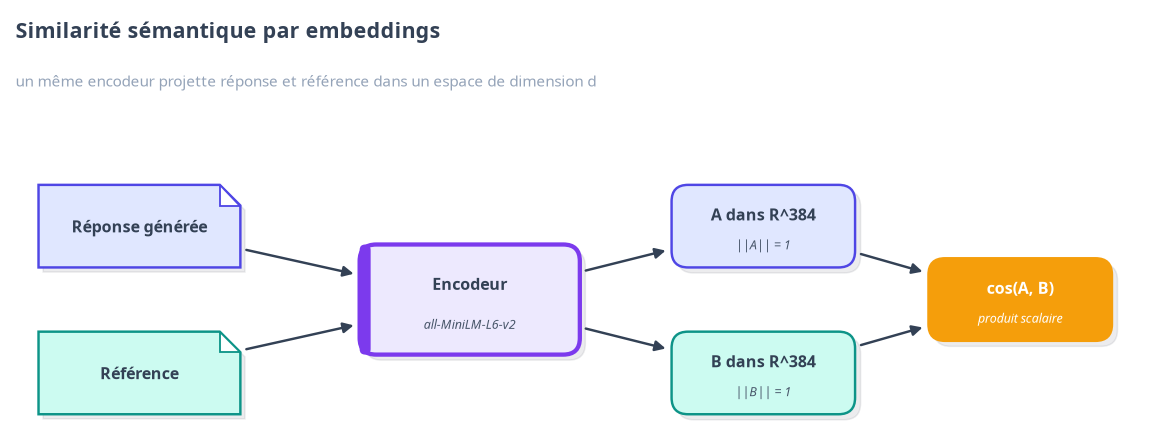

In [2]:
d = Diagram(12.5, 3.6, title="Similarité sémantique par embeddings",
            subtitle="un même encodeur projette réponse et référence dans un espace de dimension d")
d.box("gen", 1.4, 2.2, "Réponse générée", color=INDIGO, kind="doc", w=2.2, h=0.9)
d.box("ref", 1.4, 0.6, "Référence", color=TEAL, kind="doc", w=2.2, h=0.9)
d.box("enc", 5.0, 1.4, "Encodeur", sub="all-MiniLM-L6-v2", color=VIOLET, kind="model", w=2.4, h=1.2)
d.box("a", 8.2, 2.2, "A dans R^384", sub="||A|| = 1", color=INDIGO, w=2.0)
d.box("b", 8.2, 0.6, "B dans R^384", sub="||B|| = 1", color=TEAL, w=2.0)
d.box("cos", 11.0, 1.4, "cos(A, B)", sub="produit scalaire", color=AMBER, w=2.0, filled=True)
d.arrow("gen", "enc"); d.arrow("ref", "enc"); d.arrow("enc", "a"); d.arrow("enc", "b")
d.arrow("a", "cos"); d.arrow("b", "cos")
d.show()

Comparons les métriques lexicales du cours 2 et la similarité cosinus (modèle
`all-MiniLM-L6-v2`, 384 dimensions) sur des paires choisies pour piéger l'une ou
l'autre.

In [3]:
paires = [
    ("What's up?", "How are you?", "même sens, mots différents"),
    ("The movie was fantastic.", "I really loved this film.", "même sens, mots différents"),
    ("The cat sat on the mat.", "On the mat sat the cat.", "même sens, ordre changé"),
    ("Let's eat, grandma.", "Let's eat grandma.", "sens opposé, forme quasi identique"),
    ("The test passed.", "The test did not pass.", "négation"),
    ("Paris is the capital of France.", "Berlin is the capital of France.", "fait faux, forme identique"),
    ("The stock market fell sharply today.", "My grandmother bakes delicious bread.", "sans rapport"),
]
E1 = llm.embed([a for a, _, _ in paires])
E2 = llm.embed([b for _, b, _ in paires])
sim = pd.DataFrame([dict(paire=f"{a} | {b}", situation=s, edition=ev.edit_similarity(a.lower(), b.lower()),
                         bleu=ev.bleu(a, b), rouge_l=ev.rouge_l(a, b)["f1"], cosinus=float(e1 @ e2))
                    for (a, b, s), e1, e2 in zip(paires, E1, E2)])
sim

,paire,situation,edition,bleu,rouge_l,cosinus
0,What's up? | How are you?,"même sens, mots différents",0.250,0.000,0.000,0.425
1,The movie was fantastic. | I really loved this film.,"même sens, mots différents",0.160,0.000,0.000,0.709
2,The cat sat on the mat. | On the mat sat the cat.,"même sens, ordre changé",0.652,0.508,0.500,0.894
3,"Let's eat, grandma. | Let's eat grandma.","sens opposé, forme quasi identique",0.947,1.000,1.000,0.958
4,The test passed. | The test did not pass.,négation,0.545,0.296,0.500,0.744
5,Paris is the capital of France. | Berlin is the capital ...,"fait faux, forme identique",0.875,0.803,0.833,0.717
6,The stock market fell sharply today. | My grandmother ba...,sans rapport,0.189,0.000,0.000,0.017


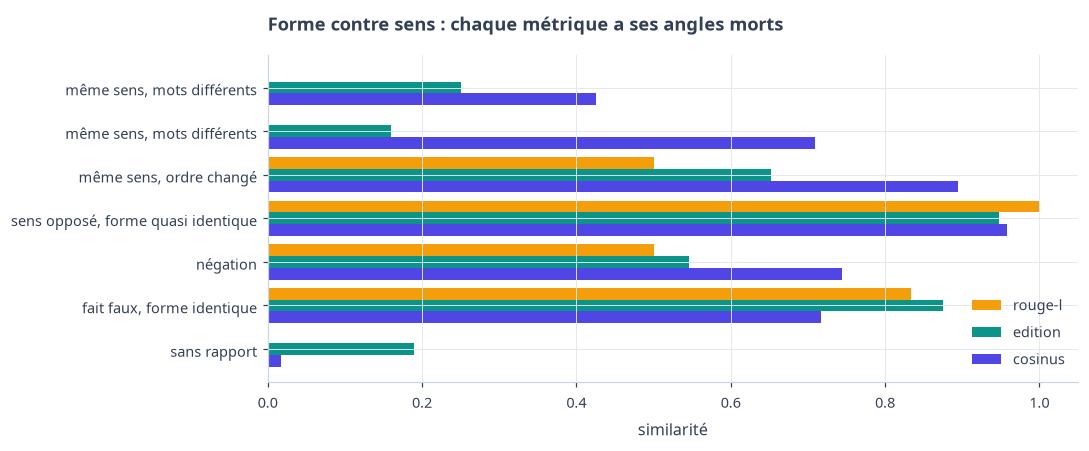

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(sim))
for k, (col, c) in enumerate([("rouge_l", AMBER), ("edition", TEAL), ("cosinus", INDIGO)]):
    ax.barh(y + (k - 1) * 0.27, sim[col], height=0.27, color=c, label=col.replace("_", "-"))
ax.set_yticks(y); ax.set_yticklabels(sim.situation); ax.invert_yaxis()
ax.set_xlabel("similarité"); ax.set_xlim(0, 1.05)
ax.set_title("Forme contre sens : chaque métrique a ses angles morts")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Les embeddings reconnaissent les paraphrases (« What's up? » / « How are you? ») là où
ROUGE-L et la distance d'édition échouent. Mais ils ont leurs propres angles morts : une
négation ou un fait faux (« Berlin is the capital of France ») gardent un cosinus élevé,
car le **sujet** est le même. La similarité sémantique mesure la proximité thématique
plus que la vérité. Le livre note aussi qu'elle dépend entièrement de la qualité de
l'encodeur (c'est pourquoi on peut la considérer comme partiellement subjective) et
qu'elle coûte un passage dans un réseau de neurones. Des métriques comme BERTScore
raffinent l'idée en alignant les embeddings **token par token**.

> **À retenir.** La similarité sémantique compare des embeddings par le cosinus. Elle
> tolère les paraphrases, demande moins de références que les métriques lexicales, mais
> reste aveugle à la négation et aux erreurs factuelles qui ne changent pas le sujet.

## 2. Introduction aux embeddings (section *Introduction to Embedding*)

Un **embedding** est une représentation vectorielle qui cherche à capturer le sens d'une
donnée. Les tailles typiques vont de quelques centaines à quelques milliers de
composantes (384 pour notre modèle, 768 pour BERT-base, 1 536 ou 3 072 pour les modèles
d'embeddings d'OpenAI d'après le tableau 3-2), bien moins que la dimension des données
brutes. Comment vérifier qu'un embedding « capture le sens » ? Le critère du livre :
des textes plus similaires doivent avoir des embeddings plus proches. Testons-le sur 24
phrases de quatre thèmes, dont les trois phrases du livre.

In [5]:
corpus = {
    "animaux": ["the cat sits on a mat", "the dog plays on the grass", "a horse runs across the field",
                "birds are singing in the trees", "my rabbit eats carrots every morning", "the puppy chased its tail"],
    "cuisine": ["she baked a chocolate cake for dessert", "add salt and pepper to the soup",
                "this restaurant serves excellent pasta", "slice the onions before frying them",
                "fresh bread smells wonderful", "he grilled vegetables for dinner"],
    "IA": ["AI research is super fun", "the neural network was trained on GPUs",
           "large language models predict the next token", "we evaluated the model on a benchmark",
           "embeddings map sentences to vectors", "the transformer uses attention layers"],
    "sport": ["the striker scored a goal in the final minute", "she won the tennis match in three sets",
              "the marathon starts at eight", "our team lost the basketball game",
              "he trains at the swimming pool daily", "the cyclist climbed the mountain stage"],
}
phrases = [p for v in corpus.values() for p in v]
themes = [t for t, v in corpus.items() for _ in v]
E = llm.embed(phrases)
print("dimension :", E.shape[1], " | normes :", np.round(np.linalg.norm(E, axis=1)[:3], 3))
S = E @ E.T
book = pd.Series({"« the dog plays on the grass »": S[0, 1], "« AI research is super fun »": S[0, 12]},
                 name="cosinus avec « the cat sits on a mat »")
book.to_frame()

dimension : 384  | normes : [1. 1. 1.]


,cosinus avec « the cat sits on a mat »
« the dog plays on the grass »,0.272
« AI research is super fun »,-0.050


Le critère du livre est vérifié : « the cat sits on a mat » est plus proche de « the dog
plays on the grass » que de « AI research is super fun ». La matrice complète et une
projection en deux dimensions (analyse en composantes principales, qui conserve les
directions de plus grande variance) montrent la structure par thèmes.

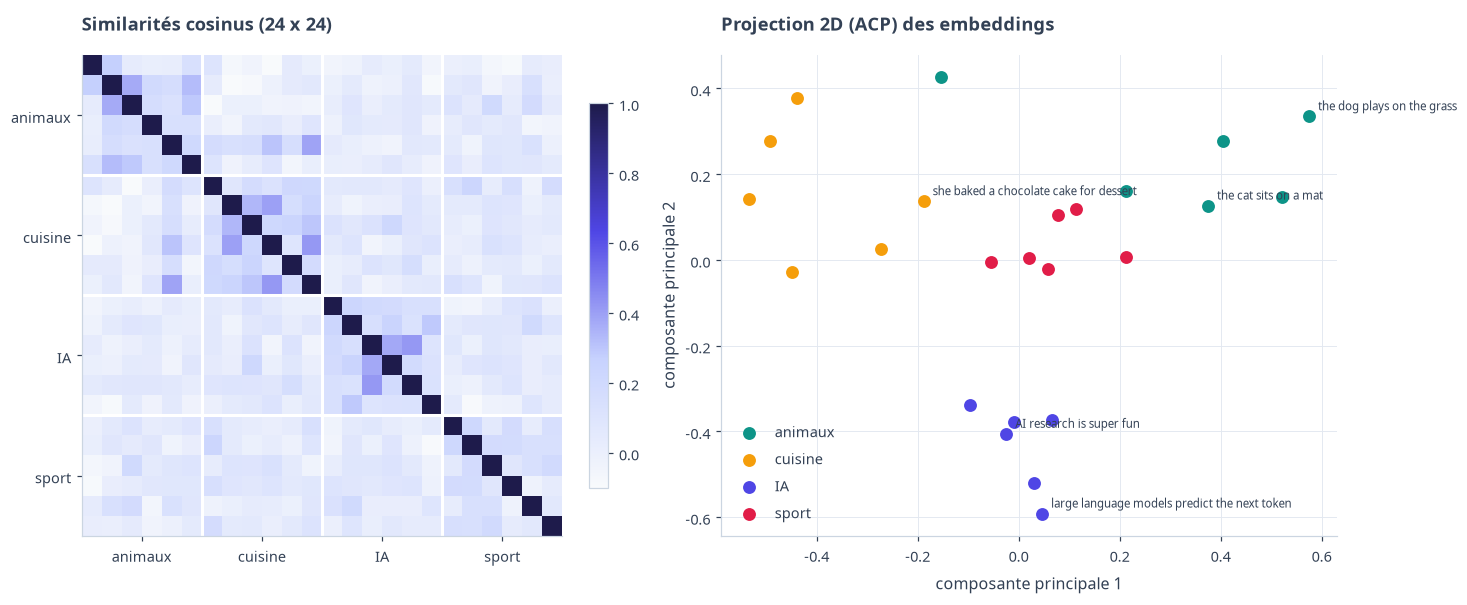

In [6]:
couleur = {"animaux": TEAL, "cuisine": AMBER, "IA": INDIGO, "sport": ROSE}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
im = ax1.imshow(S, cmap="aie_seq", vmin=-0.1, vmax=1)
for k in range(1, 4):
    ax1.axhline(6 * k - 0.5, color="white", lw=2); ax1.axvline(6 * k - 0.5, color="white", lw=2)
ax1.set_xticks([2.5, 8.5, 14.5, 20.5]); ax1.set_xticklabels(corpus.keys())
ax1.set_yticks([2.5, 8.5, 14.5, 20.5]); ax1.set_yticklabels(corpus.keys())
ax1.grid(False); ax1.set_title("Similarités cosinus (24 x 24)")
plt.colorbar(im, ax=ax1, fraction=0.046, shrink=0.8)
Z = PCA(n_components=2, random_state=0).fit_transform(E)
for t in corpus:
    idx = [i for i, x in enumerate(themes) if x == t]
    ax2.scatter(Z[idx, 0], Z[idx, 1], color=couleur[t], s=55, label=t, zorder=3)
for i in [0, 1, 12, 6, 14]:
    ax2.annotate(phrases[i], Z[i], (6, 4), textcoords="offset points", fontsize=7.5, color=SLATE)
ax2.set_xlabel("composante principale 1"); ax2.set_ylabel("composante principale 2")
ax2.set_title("Projection 2D (ACP) des embeddings")
ax2.legend(loc="best")
finish(fig)
plt.show()

Les blocs diagonaux (même thème) sont nettement plus clairs : les phrases d'un même
thème sont proches. Remarquez deux propriétés pratiques :

- les similarités entre thèmes différents ne sont pas centrées sur 0 mais légèrement
  positives : un cosinus « élevé » n'a de sens que relativement à une distribution de
  référence, d'où l'intérêt de calibrer un seuil sur ses propres données ;
- la projection 2D ne conserve qu'une partie de l'information (la variance expliquée est
  faible en dimension 384) : elle illustre, elle ne mesure pas.

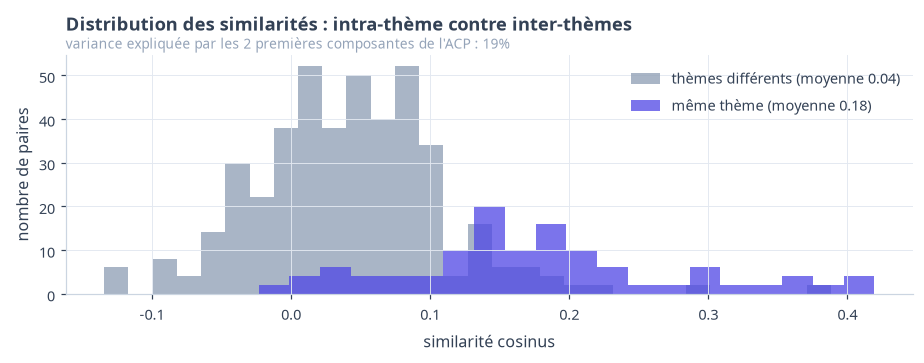

In [7]:
intra = S[np.equal.outer(themes, themes) & ~np.eye(24, dtype=bool)]
inter = S[~np.equal.outer(themes, themes)]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(inter, bins=30, color=GRAY, alpha=0.8, label=f"thèmes différents (moyenne {inter.mean():.2f})")
ax.hist(intra, bins=20, color=INDIGO, alpha=0.75, label=f"même thème (moyenne {intra.mean():.2f})")
ax.set_xlabel("similarité cosinus"); ax.set_ylabel("nombre de paires")
ax.set_title("Distribution des similarités : intra-thème contre inter-thèmes")
subtitle(ax, f"variance expliquée par les 2 premières composantes de l'ACP : "
             f"{PCA(2).fit(E).explained_variance_ratio_.sum():.0%}")
ax.legend()
plt.tight_layout(); plt.show()

**Usages.** Le livre rappelle que la similarité sert bien au-delà de l'évaluation :
recherche (chapitre 6), classement, regroupement, détection d'anomalies, déduplication
(chapitre 8). Une requête de recherche sémantique en une ligne :

In [8]:
requete = "which sentence talks about machine learning hardware?"
scores = E @ llm.embed(requete)[0]
pd.DataFrame({"phrase": np.array(phrases)[np.argsort(-scores)[:3]], "cosinus": np.sort(scores)[::-1][:3]})

,phrase,cosinus
0,the neural network was trained on GPUs,0.437
1,embeddings map sentences to vectors,0.304
2,AI research is super fun,0.280


**Embeddings multimodaux.** CLIP (Radford et al., 2021) apprend un **espace joint** pour
le texte et l'image à partir de paires (image, légende) : un encodeur par modalité, une
projection vers un espace commun, et un objectif **contrastif** qui rapproche
l'embedding d'une image de celui de sa légende et l'éloigne des autres légendes du lot.
On peut alors chercher des images avec du texte. ULIP et ImageBind étendent l'idée à la
3D, à l'audio et à d'autres modalités.

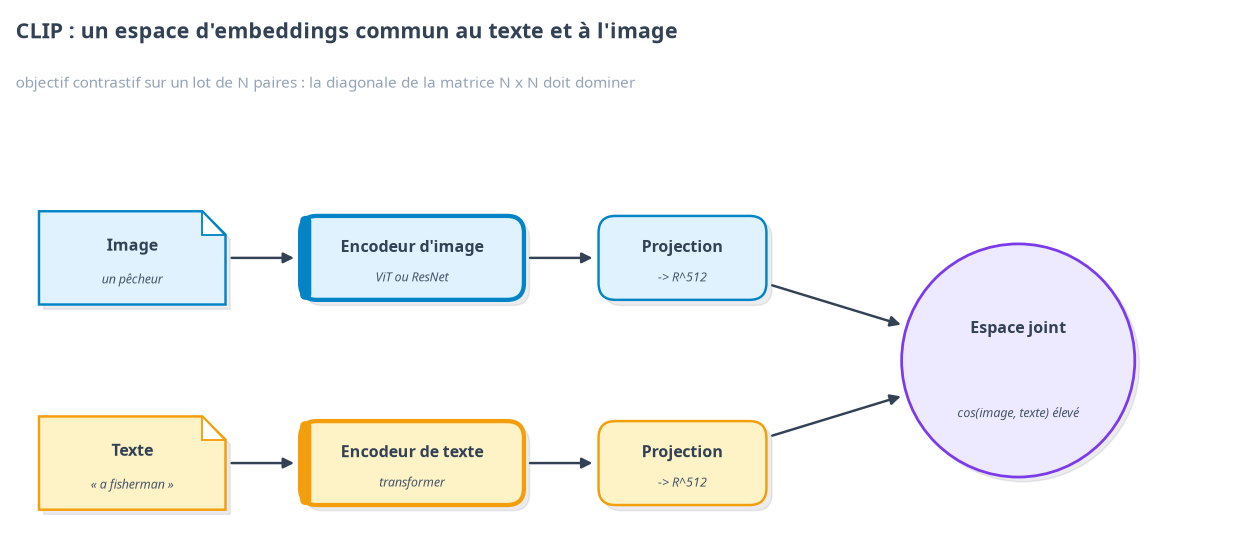

In [9]:
d = Diagram(13, 4.8, title="CLIP : un espace d'embeddings commun au texte et à l'image",
            subtitle="objectif contrastif sur un lot de N paires : la diagonale de la matrice N x N doit dominer")
d.box("img", 1.3, 3.1, "Image", sub="un pêcheur", color=SKY, kind="doc", w=2.0, h=1.0)
d.box("txt", 1.3, 0.9, "Texte", sub="« a fisherman »", color=AMBER, kind="doc", w=2.0, h=1.0)
d.box("ei", 4.3, 3.1, "Encodeur d'image", sub="ViT ou ResNet", color=SKY, kind="model", w=2.4)
d.box("et", 4.3, 0.9, "Encodeur de texte", sub="transformer", color=AMBER, kind="model", w=2.4)
d.box("pi", 7.2, 3.1, "Projection", sub="-> R^512", color=SKY, w=1.8)
d.box("pt", 7.2, 0.9, "Projection", sub="-> R^512", color=AMBER, w=1.8)
d.box("space", 10.8, 2.0, "Espace joint", sub="cos(image, texte) élevé", color=VIOLET, kind="circle", w=2.5)
d.arrow("img", "ei"); d.arrow("txt", "et"); d.arrow("ei", "pi"); d.arrow("et", "pt")
d.arrow("pi", "space"); d.arrow("pt", "space")
d.show()

> **À retenir.** Un embedding est un vecteur de quelques centaines à quelques milliers de
> dimensions ; un bon encodeur rapproche les données de sens voisin, ce qu'on vérifie
> par la similarité cosinus ou sur des benchmarks comme MTEB. Les embeddings sont au cœur
> de la recherche, du RAG et de la déduplication, et peuvent être multimodaux (CLIP).

## 3. L'IA comme juge : principe et grille (sections *AI as a Judge*, *Why AI as a Judge?*, *How to Use AI as a Judge*)

**Motivation.** Les réponses ouvertes résistent aux métriques exactes et l'évaluation
humaine est lente et chère. Idée : demander à un modèle d'évaluer les sorties d'un
autre. Les juges IA sont rapides, bon marché, flexibles (n'importe quel critère :
justesse, toxicité, fidélité au contexte...) et peuvent se passer de référence, donc
fonctionner en production. Le livre cite des accords juge-humain de l'ordre de 85 %
(GPT-4 sur MT-Bench), supérieurs à l'accord entre humains.

Trois usages, illustrés par les prompts naïfs du livre :

1. **ponctuel** : noter une réponse seule (par exemple de 1 à 5) ;
2. **avec référence** : dire si la réponse équivaut à une réponse de référence ;
3. **par paires** : désigner la meilleure de deux réponses (utile pour les données de
   préférence et le classement comparatif du cours 4).

Un prompt de juge doit préciser la **tâche**, les **critères** et le **système de
notation** (classes, notes discrètes, ou valeurs continues : les modèles réussissent
mieux avec des classes ou une petite échelle discrète, typiquement 1 à 5). Surtout : un
juge n'est pas un modèle mais un **système** modèle + prompt + paramètres
d'échantillonnage ; changer l'un des trois change le juge.

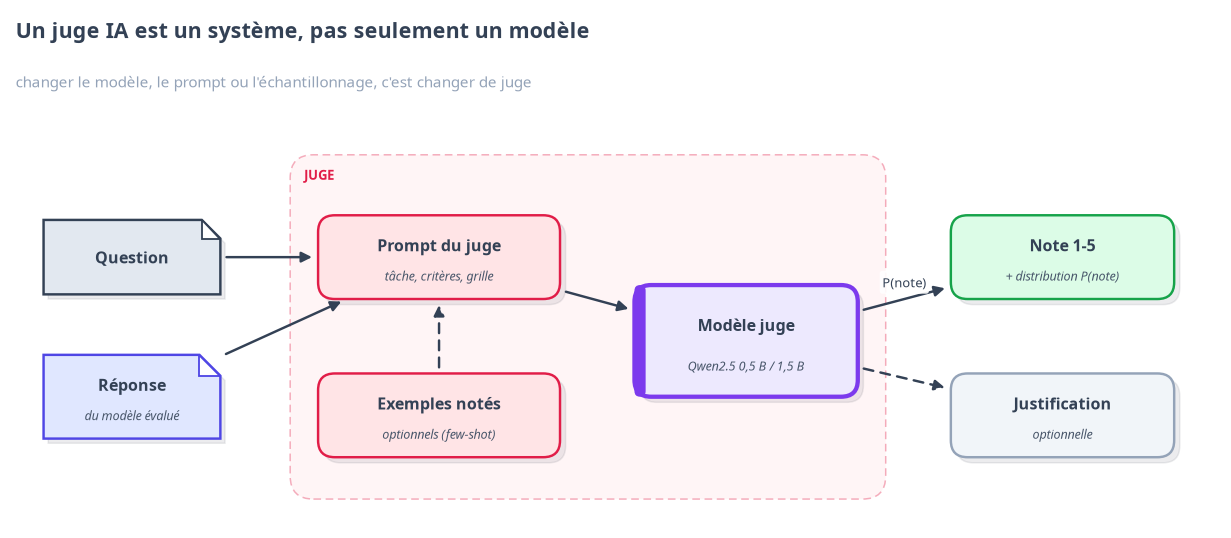

In [10]:
d = Diagram(13, 4.6, title="Un juge IA est un système, pas seulement un modèle",
            subtitle="changer le modèle, le prompt ou l'échantillonnage, c'est changer de juge")
d.group(3.0, 0.3, 9.4, 4.0, "juge", ROSE)
d.box("q", 1.3, 2.9, "Question", color=SLATE, kind="doc", w=1.9, h=0.8)
d.box("r", 1.3, 1.4, "Réponse", sub="du modèle évalué", color=INDIGO, kind="doc", w=1.9, h=0.9)
d.box("p", 4.6, 2.9, "Prompt du juge", sub="tâche, critères, grille", color=ROSE, w=2.6)
d.box("ex", 4.6, 1.2, "Exemples notés", sub="optionnels (few-shot)", color=ROSE, w=2.6)
d.box("m", 7.9, 2.0, "Modèle juge", sub="Qwen2.5 0,5 B / 1,5 B", color=VIOLET, kind="model", w=2.4, h=1.2)
d.box("s", 11.3, 2.9, "Note 1-5", sub="+ distribution P(note)", color=GREEN, w=2.4)
d.box("e", 11.3, 1.2, "Justification", sub="optionnelle", color=GRAY, w=2.4)
d.arrow("q", "p"); d.arrow("r", "p"); d.arrow("ex", "p", style="dashed"); d.arrow("p", "m")
d.arrow("m", "s", "P(note)"); d.arrow("m", "e", style="dashed")
d.show()

**Notre juge.** Grille de 1 à 5 (`ev.RUBRIC_1_5`), modèles Qwen2.5-Instruct. Plutôt que
de générer un texte puis de le parser, on lit en une seule passe avant la
**distribution** du premier token de réponse sur les cinq chiffres, après le préfixe
« Score: ». On en déduit la note la plus probable et la **note attendue**
$\mathbb E[s] = \sum_s s\,P(s)$, plus fine et plus stable qu'une note tirée au sort
(c'est l'idée de G-Eval). Voici le prompt complet pour une réponse :

In [11]:
print(ev.RUBRIC_1_5 + "\n\nQUESTION: What is the capital of Australia?\nANSWER: The capital of Australia is Sydney.")

You are a strict grader. Rate the ANSWER to the QUESTION for factual correctness and helpfulness.
Scoring rubric:
1 = wrong or irrelevant answer.
2 = mostly wrong, with a small correct element.
3 = partially correct or incomplete.
4 = correct but with a minor flaw.
5 = fully correct, clear and complete.
Reply with a single digit from 1 to 5.

QUESTION: What is the capital of Australia?
ANSWER: The capital of Australia is Sydney.


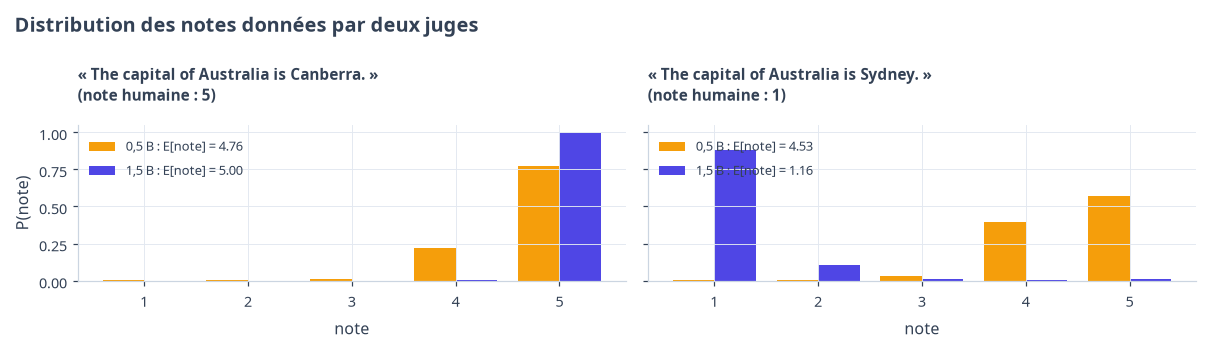

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (q, a, h) in zip(axes, [ev.JUDGE_QA[0], ev.JUDGE_QA[1]]):
    for mid, c, dx in [(llm.SMALL, AMBER, -0.2), (llm.MEDIUM, INDIGO, 0.2)]:
        j = ev.judge_pointwise(q, a, mid)
        ax.bar(np.arange(1, 6) + dx, [j["probs"][str(s)] for s in range(1, 6)], width=0.4, color=c,
               label=f"{'0,5 B' if mid == llm.SMALL else '1,5 B'} : E[note] = {j['score']:.2f}")
    ax.set_title(f"« {a} »\n(note humaine : {h})", fontsize=10)
    ax.set_xlabel("note"); ax.legend(fontsize=8.5, loc="upper left")
axes[0].set_ylabel("P(note)")
finish(fig, "Distribution des notes données par deux juges")
plt.show()

> **À retenir.** Un juge IA se définit par son modèle, son prompt (tâche, critères,
> grille, exemples) et son échantillonnage. Lire la distribution des notes plutôt
> qu'une note générée donne un score continu, déterministe et peu coûteux.

## 4. Quel modèle peut juger ? (section *What Models Can Act as Judges?*)

Le livre discute juges plus forts, égaux ou plus faibles que le modèle évalué, et note
que les juges plus forts s'accordent mieux avec les humains (Zheng et al., 2023).
Mesurons-le : 16 réponses notées par un humain (`ev.JUDGE_QA`), deux juges de tailles
différentes, et la corrélation de rang de Spearman entre notes humaines et notes
attendues.

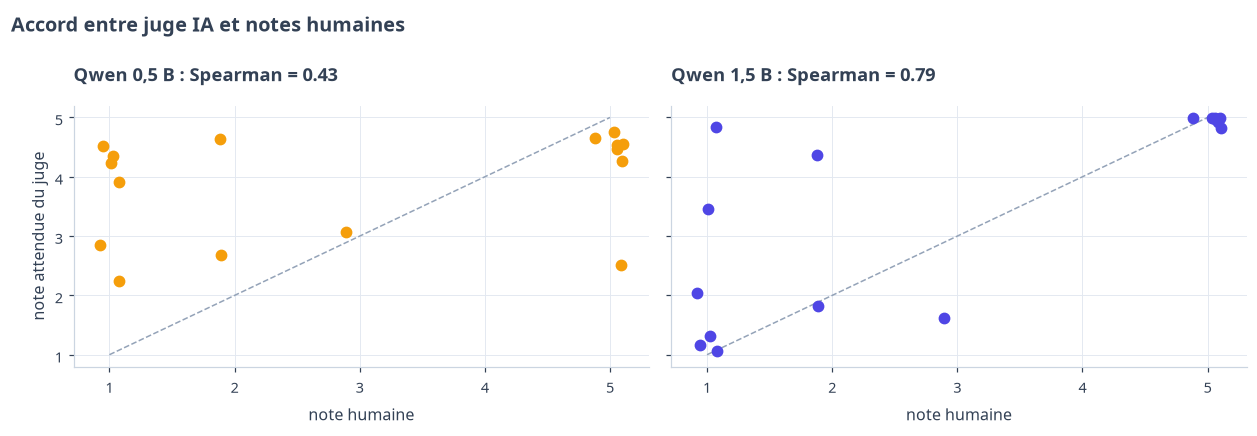

In [13]:
t0 = time.time()
rows = []
for q, a, h in ev.JUDGE_QA:
    for nom, mid in [("Qwen 0,5 B", llm.SMALL), ("Qwen 1,5 B", llm.MEDIUM)]:
        j = ev.judge_pointwise(q, a, mid)
        rows.append(dict(juge=nom, question=q, reponse=a, humain=h, note=j["score"], argmax=j["argmax"]))
J = pd.DataFrame(rows)
duree_juge = (time.time() - t0) / len(J)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for ax, (nom, g), c in zip(axes, J.groupby("juge"), [AMBER, INDIGO]):
    jit = np.random.default_rng(0).uniform(-0.12, 0.12, len(g))
    ax.scatter(g.humain + jit, g.note, color=c, s=45, zorder=3)
    ax.plot([1, 5], [1, 5], color=GRAY, ls="--", lw=1)
    rho = spearmanr(g.humain, g.note).statistic
    ax.set_title(f"{nom} : Spearman = {rho:.2f}")
    ax.set_xlabel("note humaine"); ax.set_xticks(range(1, 6)); ax.set_ylim(0.8, 5.2)
axes[0].set_ylabel("note attendue du juge")
finish(fig, "Accord entre juge IA et notes humaines")
plt.show()

Le juge de 0,5 milliard de paramètres donne des notes élevées à presque tout, y compris
à des réponses manifestement fausses : sa corrélation avec les humains est faible. Le
juge de 1,5 milliard sépare beaucoup mieux les bonnes et les mauvaises réponses, sans
être parfait. La taille du juge compte, ce qui justifie la pratique décrite par le
livre : un modèle bon marché génère, un modèle plus fort évalue un échantillon des
réponses. Le livre évoque aussi des juges **spécialisés** et petits (modèles de
récompense comme Cappy, juges avec référence comme Prometheus ou BLEURT, modèles de
préférence comme PandaLM ou JudgeLM), entraînés pour une seule tâche de jugement.

> **À retenir.** Un juge doit lui-même être évalué (accord avec des annotations
> humaines). Un juge trop faible note au hasard ou complaisamment ; les juges plus forts
> ou spécialisés corrèlent mieux avec les humains.

## 5. Biais de position (section *Biases of AI as a judge*)

En comparaison par paires, beaucoup de juges IA favorisent la réponse présentée en
**premier** (les humains, eux, tendent à favoriser la dernière). Protocole : pour chaque
question, une bonne et une mauvaise réponse ; on interroge le juge dans les deux ordres
et on lit $P(\text{préfère la bonne})$. Un juge sans biais donnerait la même valeur dans
les deux ordres.

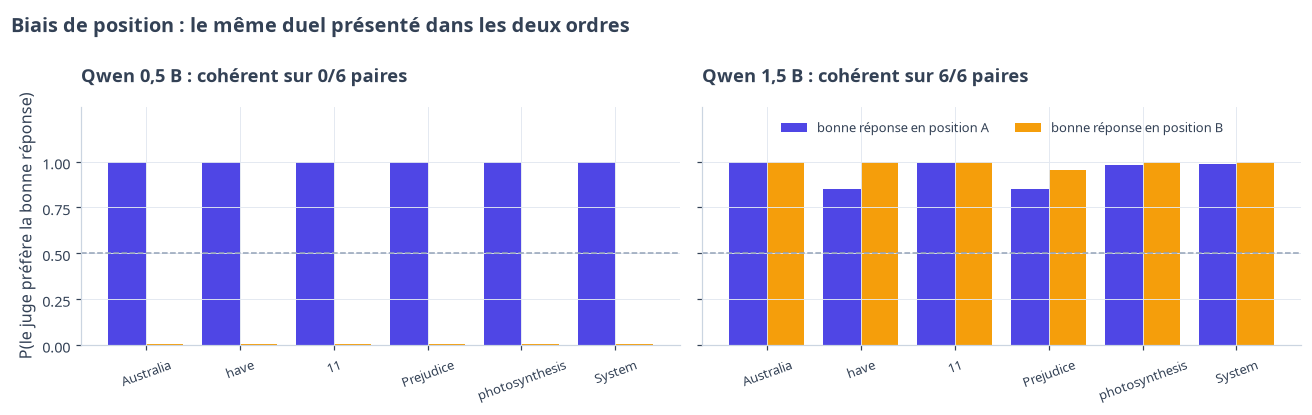

,bonne_en_A,bonne_en_B,moyenne_des_ordres,coherent
juge,,,,
"Qwen 0,5 B",0.997,0.003,0.500,0.0
"Qwen 1,5 B",0.944,0.991,0.967,1.0


In [14]:
bonnes = {q: a for q, a, h in ev.JUDGE_QA if h == 5}
mauvaises = {q: a for q, a, h in ev.JUDGE_QA if h == 1}
qs = [q for q in bonnes if q in mauvaises]
rows = []
for nom, mid in [("Qwen 0,5 B", llm.SMALL), ("Qwen 1,5 B", llm.MEDIUM)]:
    for q in qs:
        p_first = ev.judge_pairwise(q, bonnes[q], mauvaises[q], mid)         # bonne réponse en A
        p_second = 1 - ev.judge_pairwise(q, mauvaises[q], bonnes[q], mid)    # bonne réponse en B
        rows.append(dict(juge=nom, question=q, bonne_en_A=p_first, bonne_en_B=p_second))
PB = pd.DataFrame(rows)
PB["moyenne_des_ordres"] = (PB.bonne_en_A + PB.bonne_en_B) / 2
PB["coherent"] = (PB.bonne_en_A > 0.5) == (PB.bonne_en_B > 0.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (nom, g) in zip(axes, PB.groupby("juge")):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g.bonne_en_A, 0.4, color=INDIGO, label="bonne réponse en position A")
    ax.bar(x + 0.2, g.bonne_en_B, 0.4, color=AMBER, label="bonne réponse en position B")
    ax.axhline(0.5, color=GRAY, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([q.split()[-1].strip("?'") for q in g.question], fontsize=8.5, rotation=20)
    ax.set_title(f"{nom} : cohérent sur {g.coherent.sum()}/{len(g)} paires")
    ax.set_ylim(0, 1.3); ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
axes[0].set_ylabel("P(le juge préfère la bonne réponse)")
axes[1].legend(loc="upper center", fontsize=8.5, ncol=2)
finish(fig, "Biais de position : le même duel présenté dans les deux ordres")
plt.show()
PB.groupby("juge")[["bonne_en_A", "bonne_en_B", "moyenne_des_ordres", "coherent"]].mean()

Le juge de 0,5 B répond pratiquement toujours « A » : il ne juge pas, il choisit une
position. Le juge de 1,5 B est bien plus robuste sur ces duels faciles. La parade
classique, citée par le livre, consiste à **répéter le test dans les deux ordres** et à
moyenner (colonne `moyenne_des_ordres`), ou à ne retenir que les verdicts cohérents :
cela double le coût, mais neutralise le biais de premier ordre.

> **À retenir.** Toujours tester un juge par paires dans les deux ordres. Un verdict qui
> change quand on permute les réponses n'est pas un verdict.

## 6. Biais de verbosité (section *Biases of AI as a judge*)

Certains juges préfèrent les réponses **longues**, indépendamment de leur qualité : Wu
et Aji (2023) ont montré que GPT-4 et Claude-1 préféraient des réponses d'environ
100 mots contenant des erreurs à des réponses correctes de 50 mots. Reproduisons
l'expérience en miniature (`ev.VERBOSE_PAIRS`) : une réponse correcte d'un ou deux mots
contre une réponse longue, assurée et **fausse**.

In [15]:
q0, court0, long0 = ev.VERBOSE_PAIRS[2]
print(f"Q : {q0}\nCourte : {court0}\nLongue : {ev.wrap(long0, 100)}")

Q : What is 12 times 11?
Courte : 132.
Longue : To compute this product, we can decompose the multiplication: 12 times 11 equals 12 times 10 plus 12
times 1. Twelve times ten is one hundred and twenty, and adding twelve gives a total of 122.
Therefore, the final answer to 12 times 11 is 122.


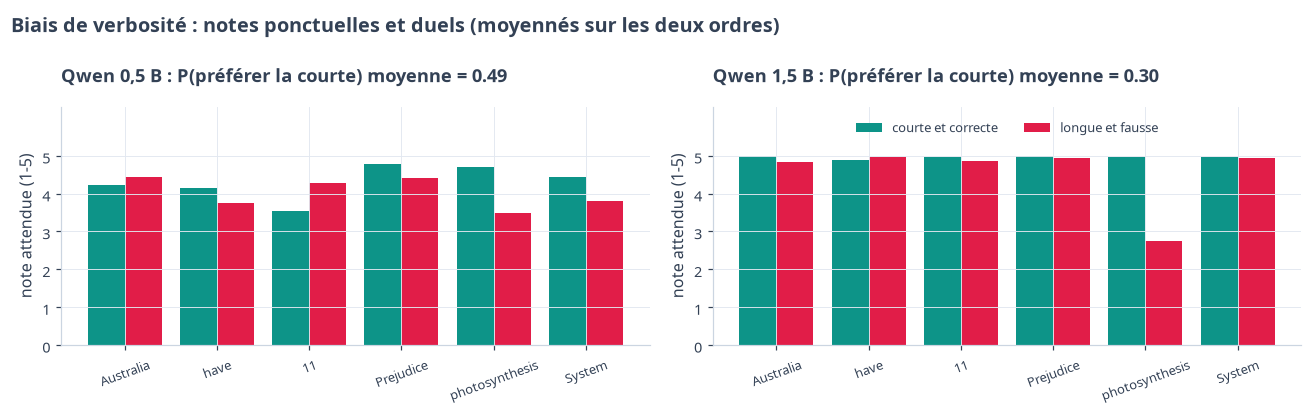

,note_courte,note_longue,P_courte_moy
juge,,,
"Qwen 0,5 B",4.303,4.027,0.493
"Qwen 1,5 B",4.966,4.551,0.303


In [16]:
rows = []
for nom, mid in [("Qwen 0,5 B", llm.SMALL), ("Qwen 1,5 B", llm.MEDIUM)]:
    for q, court, long_ in ev.VERBOSE_PAIRS:
        pa = ev.judge_pairwise(q, court, long_, mid)
        pb = 1 - ev.judge_pairwise(q, long_, court, mid)
        rows.append(dict(juge=nom, question=q, P_courte_moy=(pa + pb) / 2,
                         note_courte=ev.judge_pointwise(q, court, mid)["score"],
                         note_longue=ev.judge_pointwise(q, long_, mid)["score"]))
VB = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nom, g), c in zip(axes, VB.groupby("juge"), [AMBER, INDIGO]):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g.note_courte, 0.4, color=TEAL, label="courte et correcte")
    ax.bar(x + 0.2, g.note_longue, 0.4, color=ROSE, label="longue et fausse")
    ax.set_xticks(x); ax.set_xticklabels([q.split()[-1].strip("?'") for q in g.question], fontsize=8.5, rotation=20)
    ax.set_ylim(0, 5.4); ax.set_ylabel("note attendue (1-5)")
    ax.set_ylim(0, 6.3); ax.set_yticks(range(6))
    ax.set_title(f"{nom} : P(préférer la courte) moyenne = {g.P_courte_moy.mean():.2f}")
axes[1].legend(loc="upper center", fontsize=8.5, ncol=2)
finish(fig, "Biais de verbosité : notes ponctuelles et duels (moyennés sur les deux ordres)")
plt.show()
VB.groupby("juge")[["note_courte", "note_longue", "P_courte_moy"]].mean()

Même le juge de 1,5 B, plutôt fiable sur des réponses de même longueur (section 4),
accorde des notes élevées à plusieurs réponses longues et fausses : l'aplomb et le
vocabulaire riche masquent l'erreur. Les études citées par le livre trouvent que ce
biais diminue avec la force du juge (GPT-4 moins que GPT-3.5), sans disparaître. Parades :
exiger dans la grille que la justesse prime sur le style, contrôler la longueur (comparer
des réponses de longueurs voisines, ou corriger statistiquement comme le fait
AlpacaEval), et vérifier les juges sur des cas pièges comme ceux-ci.

> **À retenir.** Les juges IA confondent souvent longueur et qualité. Toute comparaison
> entre systèmes dont les réponses ont des longueurs différentes doit contrôler ce biais.

## 7. Incohérence et ambiguïté des critères (sections *Inconsistency* et *Criteria ambiguity*)

**Incohérence.** Un juge échantillonné à température non nulle peut donner deux notes
différentes au même contenu. Notre lecture de la distribution permet de quantifier ce
risque sans tirer : si le juge échantillonnait sa note, l'écart-type de la note serait
$\sqrt{\sum_s s^2 P(s) - \mathbb E[s]^2}$, et la probabilité que deux appels donnent la
même note serait $\sum_s P(s)^2$.

In [17]:
rows = []
for q, a, h in ev.JUDGE_QA:
    for nom, mid in [("Qwen 0,5 B", llm.SMALL), ("Qwen 1,5 B", llm.MEDIUM)]:
        pr = ev.judge_pointwise(q, a, mid)["probs"]
        p = np.array([pr[str(s)] for s in range(1, 6)])
        m = (np.arange(1, 6) * p).sum()
        rows.append(dict(juge=nom, ecart_type=np.sqrt(((np.arange(1, 6) - m) ** 2 * p).sum()),
                         P_deux_appels_identiques=(p ** 2).sum()))
pd.DataFrame(rows).groupby("juge").mean()

,ecart_type,P_deux_appels_identiques
juge,,
"Qwen 0,5 B",0.794,0.417
"Qwen 1,5 B",0.571,0.727


Avec le petit juge, deux appels échantillonnés donneraient souvent des notes
différentes. Le livre rapporte qu'ajouter des exemples au prompt fait passer la
cohérence de GPT-4 de 65 % à 77,5 % (Zheng et al.), au prix d'un prompt plus long, donc
plus cher ; et cohérence n'est pas justesse (un juge peut se tromper de façon très
reproductible).

**Ambiguïté des critères.** Il n'existe pas de standard : le même critère (« fidélité »)
est noté de 1 à 5 par MLflow, 0 ou 1 par Ragas, YES ou NO par LlamaIndex (tableau 3-4).
Notons les 16 réponses avec trois formulations d'un même critère de justesse, au même
juge de 1,5 B, puis comparons les verdicts binaires obtenus.

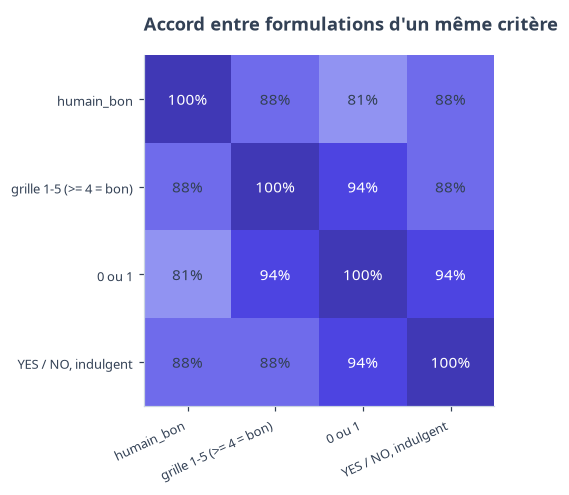

Part des réponses jugées bonnes : {'humain_bon': 0.44, 'grille 1-5 (>= 4 = bon)': 0.56, '0 ou 1': 0.62, 'YES / NO, indulgent': 0.56}


In [18]:
FORMATS = {
    "grille 1-5 (>= 4 = bon)": None,
    "0 ou 1": ("Is the ANSWER to the QUESTION factually correct? Reply 1 if correct, 0 otherwise.", ["1", "0"]),
    "YES / NO, indulgent": ("Does the ANSWER address the QUESTION in a reasonable way? Answer YES or NO.", ["YES", "NO"]),
}
rows = []
for q, a, h in ev.JUDGE_QA:
    r = dict(reponse=a[:45], humain_bon=h >= 4)
    r["grille 1-5 (>= 4 = bon)"] = ev.judge_pointwise(q, a, llm.MEDIUM)["score"] >= 3.5
    for nom, spec in list(FORMATS.items())[1:]:
        consigne, choix = spec
        pr = ev.choice_probs(f"{consigne}\n\nQUESTION: {q}\nANSWER: {a}", choix, model_id=llm.MEDIUM)
        r[nom] = pr[choix[0]] > 0.5
    rows.append(r)
CR = pd.DataFrame(rows)
cols = ["humain_bon"] + list(FORMATS)
accord = pd.DataFrame([[np.mean(CR[a] == CR[b]) for b in cols] for a in cols], index=cols, columns=cols)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.imshow(accord.values, cmap="aie_seq", vmin=0.5, vmax=1.15)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{accord.values[i, j]:.0%}", ha="center", va="center",
                color="white" if accord.values[i, j] > 0.9 else SLATE, fontsize=10)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=25, ha="right", fontsize=8.5)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8.5); ax.grid(False)
ax.set_title("Accord entre formulations d'un même critère")
plt.tight_layout(); plt.show()
print("Part des réponses jugées bonnes :", CR[cols].mean().round(2).to_dict())

Le même modèle, sur les mêmes réponses, ne donne pas les mêmes verdicts selon la
formulation du critère : les taux d'acceptation diffèrent (ligne imprimée ci-dessus,
tous supérieurs à la part de réponses bonnes selon l'humain) et l'accord entre
formulations n'est pas de 100 %. Aucune n'est « la » mesure de justesse. C'est exactement
le scénario du livre où un collègue modifie le prompt du juge et où le score de
l'application « progresse » sans que l'application ait changé. D'où la règle du livre :
ne jamais faire confiance à un juge dont on ne voit ni le modèle ni le prompt, et
**versionner** les juges comme du code.

> **À retenir.** Les scores d'un juge IA ne sont comparables qu'à juge constant (même
> modèle, même prompt, même échantillonnage). Un juge doit être figé, versionné et
> réévalué quand il change.

## 8. Coût et latence d'un juge (section *Increased costs and latency*)

**Coût.** Juger, c'est relire la question et la réponse, plus la consigne du juge.
Juger chaque réponse selon trois critères avec un modèle aussi cher que le générateur
multiplie à peu près le nombre d'appels par quatre (livre). Deux leviers : un juge moins
cher et l'**échantillonnage** (« spot-checking », n'évaluer qu'une fraction des
réponses). Le calcul ci-dessous utilise des prix **fictifs** mais d'ordre de grandeur
réaliste : générateur et juge à 2 \$ / million de tokens en entrée et 8 \$ en sortie, un
million de requêtes par mois, 400 tokens en entrée et 250 en sortie par requête, un
prompt de juge de 300 tokens et une sortie de juge de 5 tokens (une note).

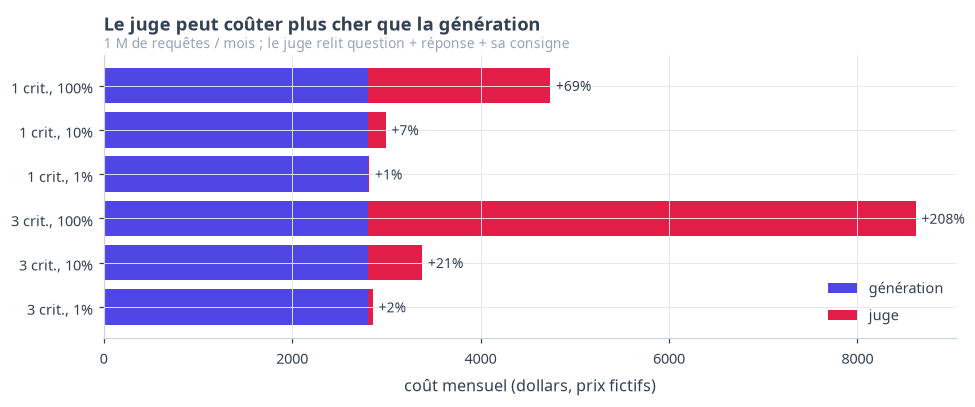

In [19]:
base = dict(n_requests=1_000_000, gen_in=400, gen_out=250, judge_out=5, price_in=2.0, price_out=8.0)
rows = []
for n_crit in [1, 3]:
    for taux in [1.0, 0.1, 0.01]:
        c = ev.judge_cost(**base, n_criteria=n_crit, sample_rate=taux)
        rows.append(dict(criteres=n_crit, fraction_jugee=taux, generation=c["generation"], juge=c["juge"],
                         surcout=c["surcout"]))
CO = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
lab = [f"{r.criteres} crit., {r.fraction_jugee:.0%}" for r in CO.itertuples()]
ax.barh(lab, CO.generation, color=INDIGO, label="génération")
ax.barh(lab, CO.juge, left=CO.generation, color=ROSE, label="juge")
for i, r in enumerate(CO.itertuples()):
    ax.text(r.generation + r.juge + 60, i, f"+{r.surcout:.0%}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("coût mensuel (dollars, prix fictifs)")
ax.set_title("Le juge peut coûter plus cher que la génération")
subtitle(ax, "1 M de requêtes / mois ; le juge relit question + réponse + sa consigne")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Juger chaque réponse sur trois critères multiplie la facture par environ **trois** (le
juge relit la question, la réponse et sa consigne une fois par critère) ; en juger 1 %
rend le surcoût négligeable. Mais combien d'échantillons faut-il pour estimer
un taux d'échec ? Avec l'approximation normale, $n = z^2\,p(1-p)/\varepsilon^2$ :

In [20]:
pd.DataFrame({f"marge ± {e:.0%}": {f"taux d'échec ~ {p:.0%}": ev.spot_check_sample_size(p, e) for p in [0.02, 0.1, 0.3]}
              for e in [0.01, 0.02, 0.05]})

,marge ± 1%,marge ± 2%,marge ± 5%
taux d'échec ~ 2%,753,189,31
taux d'échec ~ 10%,3458,865,139
taux d'échec ~ 30%,8068,2017,323


Quelques milliers de réponses jugées par mois suffisent à suivre un taux d'échec à un ou
deux points près, bien moins que le million de requêtes : l'échantillonnage est le levier
de coût le plus puissant (le chapitre 4 y revient).

**Latence.** Juger **avant** de répondre (garde-fou) ajoute la latence du juge au
parcours de l'utilisateur. Mesurons-la localement : lecture de distribution (une passe
avant) contre génération d'une justification de 60 tokens.

In [21]:
q, a, _ = ev.JUDGE_QA[1]
msg = f"{ev.RUBRIC_1_5}\n\nQUESTION: {q}\nANSWER: {a}"
for mid in [llm.SMALL, llm.MEDIUM]:
    ev.judge_pointwise(q, a, mid)  # échauffement
lat = []
for nom, mid in [("0,5 B", llm.SMALL), ("1,5 B", llm.MEDIUM)]:
    t = time.perf_counter(); [ev.judge_pointwise(q, a, mid) for _ in range(5)]; t1 = (time.perf_counter() - t) / 5
    t = time.perf_counter()
    llm.chat(msg.replace("Reply with a single digit from 1 to 5.", "Explain your grade in two sentences, then give it."),
             mid, max_new_tokens=60)
    t2 = time.perf_counter() - t
    lat.append(dict(juge=nom, lecture_distribution_ms=1000 * t1, generation_60_tokens_ms=1000 * t2))
pd.DataFrame(lat).set_index("juge").round(0)

,lecture_distribution_ms,generation_60_tokens_ms
juge,,
"0,5 B",13.0,623.0
"1,5 B",25.0,385.0


Une note lue en une passe avant coûte quelques dizaines de millisecondes ; une
justification générée coûte un ordre de grandeur de plus, proportionnellement au nombre
de tokens produits (chapitre 9). Pour un garde-fou synchrone, on privilégie donc des
juges courts (une classe, une note), voire de petits juges spécialisés ; les
justifications détaillées sont réservées à l'évaluation hors ligne.

> **À retenir.** Un juge IA ajoute un coût proportionnel aux tokens qu'il relit (souvent
> comparable à celui de la génération par critère) et une latence. On le maîtrise par
> l'échantillonnage, des juges plus petits ou spécialisés, et des sorties courtes.

## Synthèse

- **Similarité sémantique** : cosinus entre embeddings ; tolère les paraphrases, reste
  aveugle aux négations et aux erreurs factuelles de même sujet ; dépend de l'encodeur.
- **Embeddings** : vecteurs de $10^2$ à $10^4$ dimensions ; bons s'ils rapprochent les
  sens voisins ; projections 2D pour visualiser ; espaces multimodaux (CLIP).
- **IA comme juge** : système modèle + prompt + échantillonnage ; ponctuel, avec
  référence ou par paires ; lire la distribution des notes donne un score continu.
- **Limites mesurées** : juge faible peu corrélé aux humains, biais de position (parfois
  total), biais de verbosité, dépendance à la formulation, coût et latence.
- Les juges IA doivent être eux-mêmes évalués, figés, versionnés, et complétés par des
  méthodes exactes ou humaines.

**Liens.** Le cours 4 utilise les comparaisons par paires pour **classer** des modèles
(Elo, Bradley-Terry). Le chapitre 4 construira un pipeline d'évaluation complet ; le
chapitre 6 réutilise les embeddings pour la recherche ; le chapitre 2 a montré comment
l'échantillonnage influence la cohérence d'un modèle, juge compris.

In [22]:
llm.free_gpu()